# 🏢 Tashkent Real Estate: Exploratory Data Analysis & Multiple Linear Regression

### 📌 Executive Summary
This notebook conducts an end-to-end **Exploratory Data Analysis (EDA)**, **Data Cleaning**, **Feature Engineering**, and **Multiple Linear Regression (MLR)** pipeline on real estate apartment listings in Tashkent, Uzbekistan (scraped from `uybor.uz`).

**Initial Dataset Audit Summary (`uybor.xlsx`):**
- **Raw Shape:** `7,421 rows × 9 columns` (`address`, `district`, `rooms`, `size`, `level`, `max_levels`, `price`, `lat`, `lng`)
- **Missing Values:** `0` across all columns
- **Exact Duplicate Listings:** `696` duplicate rows detected
- **Price Range (Raw):** `$10,500` to `$800,000` (Mean: `$59,118`, Median: `$46,500`)
- **Area Range (Raw):** `14 m²` to `456 m²` (Mean: `73.15 m²`, Median: `65.0 m²`)

## 1. Environment Setup & Library Imports

In [1]:
# Importing data science and machine learning libraries
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Configure visual styling for clean academic plots
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['font.size'] = 11
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print('✅ All libraries imported successfully!')

✅ All libraries imported successfully!


## 2. Data Loading & Initial Inspection
We load `uybor.xlsx` (sheet `uybor_scrapping`) and inspect its structure, data types, missing values, and descriptive statistics.

In [2]:
# Loading dataset and inspecting schema
FILE_PATH = 'uybor.xlsx'
df_raw = pd.read_excel(FILE_PATH, sheet_name='uybor_scrapping')

print(f'Dataset Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns\n')
display(df_raw.head())

Dataset Shape: 7,421 rows × 9 columns



,address,district,rooms,size,level,max_levels,price,lat,lng
0,"город Ташкент, Yunusobod район, Юнусабад 8-й к...",Yunusobod,3,57.00,4,4,52000,41.37,69.28
1,"город Ташкент, Yakkasaroy район, 1-й тупик Шот...",Yakkasaroy,2,52.00,4,5,56000,41.29,69.26
2,"город Ташкент, Chilonzor район, Чиланзар 2-й к...",Chilonzor,2,42.00,4,4,37000,41.28,69.22
3,"город Ташкент, Chilonzor район, Чиланзар 9-й к...",Chilonzor,3,65.00,1,4,49500,41.29,69.20
4,"город Ташкент, Chilonzor район, площадь Актепа",Chilonzor,3,70.00,3,5,55000,41.30,69.21


In [3]:
# Checking data types, nulls, and summary statistics
print('--- DATA TYPES & NON-NULL COUNTS ---')
print(df_raw.info())

print('\n--- MISSING VALUES PER COLUMN ---')
print(df_raw.isnull().sum())

print(f'\n--- EXACT DUPLICATE ROWS: {df_raw.duplicated().sum()} ---')

print('\n--- SUMMARY STATISTICS (NUMERICAL) ---')
display(df_raw.describe().T)

--- DATA TYPES & NON-NULL COUNTS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7421 entries, 0 to 7420
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   address     7421 non-null   object 
 1   district    7421 non-null   object 
 2   rooms       7421 non-null   int64  
 3   size        7421 non-null   float64
 4   level       7421 non-null   int64  
 5   max_levels  7421 non-null   int64  
 6   price       7421 non-null   int64  
 7   lat         7421 non-null   float64
 8   lng         7421 non-null   float64
dtypes: float64(3), int64(4), object(2)
memory usage: 521.9+ KB
None

--- MISSING VALUES PER COLUMN ---
address       0
district      0
rooms         0
size          0
level         0
max_levels    0
price         0
lat           0
lng           0
dtype: int64

--- EXACT DUPLICATE ROWS: 696 ---

--- SUMMARY STATISTICS (NUMERICAL) ---


,count,mean,std,min,25%,50%,75%,max
rooms,"7,421.00",2.62,1.08,1.00,2.00,3.00,3.00,10.00
size,"7,421.00",73.15,37.00,14.00,50.00,65.00,85.00,456.00
level,"7,421.00",3.70,2.24,1.00,2.00,3.00,5.00,19.00
max_levels,"7,421.00",6.03,2.61,1.00,4.00,5.00,9.00,25.00
price,"7,421.00","59,117.62","46,701.09","10,500.00","35,000.00","46,500.00","66,847.00","800,000.00"
lat,"7,421.00",41.30,0.03,41.19,41.28,41.30,41.32,41.42
lng,"7,421.00",69.26,0.06,69.15,69.21,69.26,69.29,69.59


In [4]:
# Inspecting categorical district distribution
print('--- APARTMENT COUNT BY TASHKENT DISTRICT ---')
district_counts = df_raw['district'].value_counts().reset_index()
district_counts.columns = ['District', 'Listing Count']
district_counts['Percentage (%)'] = (district_counts['Listing Count'] / len(df_raw)) * 100
display(district_counts)

--- APARTMENT COUNT BY TASHKENT DISTRICT ---


,District,Listing Count,Percentage (%)
0,Chilonzor,1629,21.95
1,Mirzo Ulugbek,1360,18.33
2,Yunusobod,873,11.76
3,Uchtepa,870,11.72
4,Mirobod,767,10.34
5,Yakkasaroy,647,8.72
6,Yashnobod,459,6.19
7,Shayhontohur,371,5.00
8,Olmzor,264,3.56
9,Sergeli,159,2.14


## 3. Data Cleaning & Anomaly Detection
Before training a **Multiple Linear Regression** model, we must clean structural errors and severe outliers because Ordinary Least Squares (OLS) minimizes squared residuals ($\sum (y_i - \hat{y}_i)^2$) and is highly sensitive to extreme outliers.

**Cleaning Steps Performed:**
1. **Remove Exact Duplicates:** Drop the `696` duplicated rows (`7,421 → 6,725` unique records).
2. **Logical Consistency Check (`level <= max_levels`):** Ensure the apartment floor (`level`) never exceeds the total building height (`max_levels`).
3. **Room vs. Area Consistency:** Ensure minimum realistic room area (`size / rooms >= 9 m²`).
4. **Statistical Outlier Filtering:** Compute `price_per_sqm = price / size` and filter out extreme scraping errors and ultra-luxury penthouses (keeping the 1st to 99th percentiles of `price`, `size`, and `price_per_sqm`).

In [5]:
# Removing duplicates and domain anomalies
df = df_raw.copy()
initial_rows = len(df)

# 1. Drop exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)
after_dedup = len(df)
print(f'1. Removed {initial_rows - after_dedup} duplicate rows -> {after_dedup:,} rows remaining.')

# 2. Check logical floor consistency (level <= max_levels)
invalid_levels = df[df['level'] > df['max_levels']]
print(f'2. Found {len(invalid_levels)} rows where floor level > max_levels.')
df = df[df['level'] <= df['max_levels']].copy()

# 3. Create helper diagnostic features
df['price_per_sqm'] = df['price'] / df['size']
df['sqm_per_room'] = df['size'] / df['rooms']

# 4. Filter out unrealistic scraping anomalies & extreme 1% tails
p_low, p_high = df['price'].quantile([0.01, 0.99])
s_low, s_high = df['size'].quantile([0.01, 0.99])
pps_low, pps_high = df['price_per_sqm'].quantile([0.01, 0.99])

df_clean = df[
    (df['price'].between(p_low, p_high)) &
    (df['size'].between(s_low, s_high)) &
    (df['price_per_sqm'].between(pps_low, pps_high)) &
    (df['sqm_per_room'] >= 9.0) &
    (df['rooms'] <= 6)
].reset_index(drop=True)

print(f'3. Removed {len(df) - len(df_clean)} extreme outliers/anomalies.')
print(f'✅ Final Clean Dataset Shape: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns')
display(df_clean.describe().T)

1. Removed 696 duplicate rows -> 6,725 rows remaining.
2. Found 0 rows where floor level > max_levels.
3. Removed 276 extreme outliers/anomalies.
✅ Final Clean Dataset Shape: 6,449 rows × 11 columns


,count,mean,std,min,25%,50%,75%,max
rooms,"6,449.00",2.60,1.01,1.00,2.00,3.00,3.00,6.00
size,"6,449.00",71.03,28.82,24.00,50.00,65.00,84.00,215.00
level,"6,449.00",3.71,2.24,1.00,2.00,3.00,5.00,18.00
max_levels,"6,449.00",6.02,2.60,1.00,4.00,5.00,9.00,25.00
price,"6,449.00","55,758.65","31,933.04","17,700.00","35,000.00","46,500.00","65,000.00","265,000.00"
lat,"6,449.00",41.30,0.03,41.19,41.28,41.30,41.32,41.42
lng,"6,449.00",69.26,0.06,69.15,69.21,69.26,69.29,69.59
price_per_sqm,"6,449.00",773.92,215.37,409.09,625.00,722.22,876.67,"1,632.65"
sqm_per_room,"6,449.00",28.41,7.05,10.00,23.50,26.67,31.33,72.50


## 4. Exploratory Data Analysis (EDA) & Visualizations
Let's visually explore the cleaned dataset to answer key questions for our presentation:
1. **Distribution Comparison:** How did cleaning improve the skewness of `price` and `size`?
2. **District Analysis:** Which Tashkent districts are the most expensive in total price and price per $m^2$?
3. **Bivariate Relationships:** How strongly does `size` ($m^2$) drive `price` across room counts?
4. **Geospatial Price Heatmap:** How do prices vary geographically across Tashkent (`lat`, `lng`)?

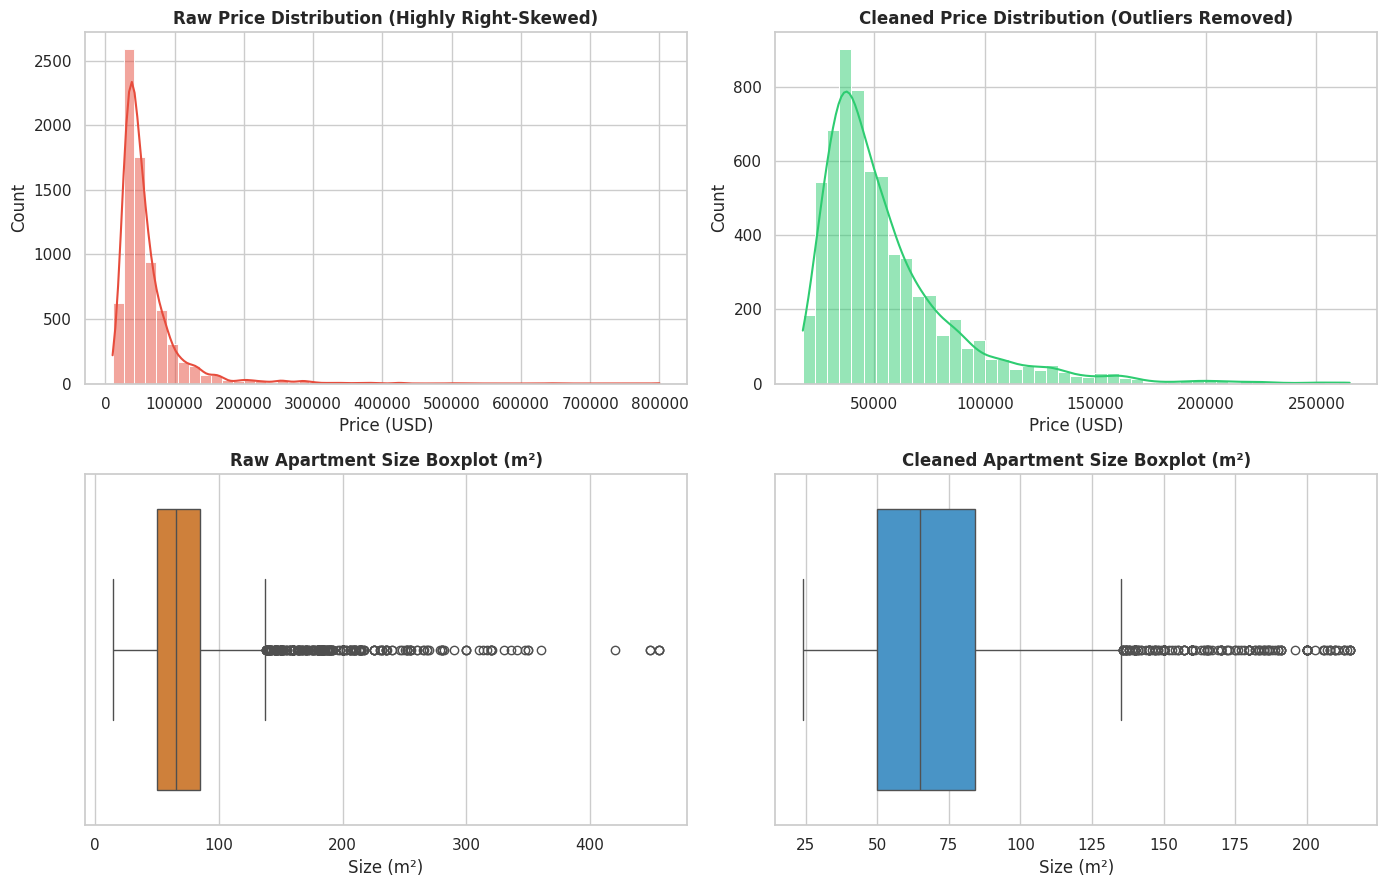

In [6]:
# Plotting raw vs cleaned price and size distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Raw Price
sns.histplot(df_raw['price'], bins=50, kde=True, ax=axes[0, 0], color='#e74c3c')
axes[0, 0].set_title('Raw Price Distribution (Highly Right-Skewed)', fontweight='bold')
axes[0, 0].set_xlabel('Price (USD)')

# Cleaned Price
sns.histplot(df_clean['price'], bins=45, kde=True, ax=axes[0, 1], color='#2ecc71')
axes[0, 1].set_title('Cleaned Price Distribution (Outliers Removed)', fontweight='bold')
axes[0, 1].set_xlabel('Price (USD)')

# Raw Size
sns.boxplot(x=df_raw['size'], ax=axes[1, 0], color='#e67e22')
axes[1, 0].set_title('Raw Apartment Size Boxplot (m²)', fontweight='bold')
axes[1, 0].set_xlabel('Size (m²)')

# Cleaned Size
sns.boxplot(x=df_clean['size'], ax=axes[1, 1], color='#3498db')
axes[1, 1].set_title('Cleaned Apartment Size Boxplot (m²)', fontweight='bold')
axes[1, 1].set_xlabel('Size (m²)')

plt.tight_layout()
plt.show()

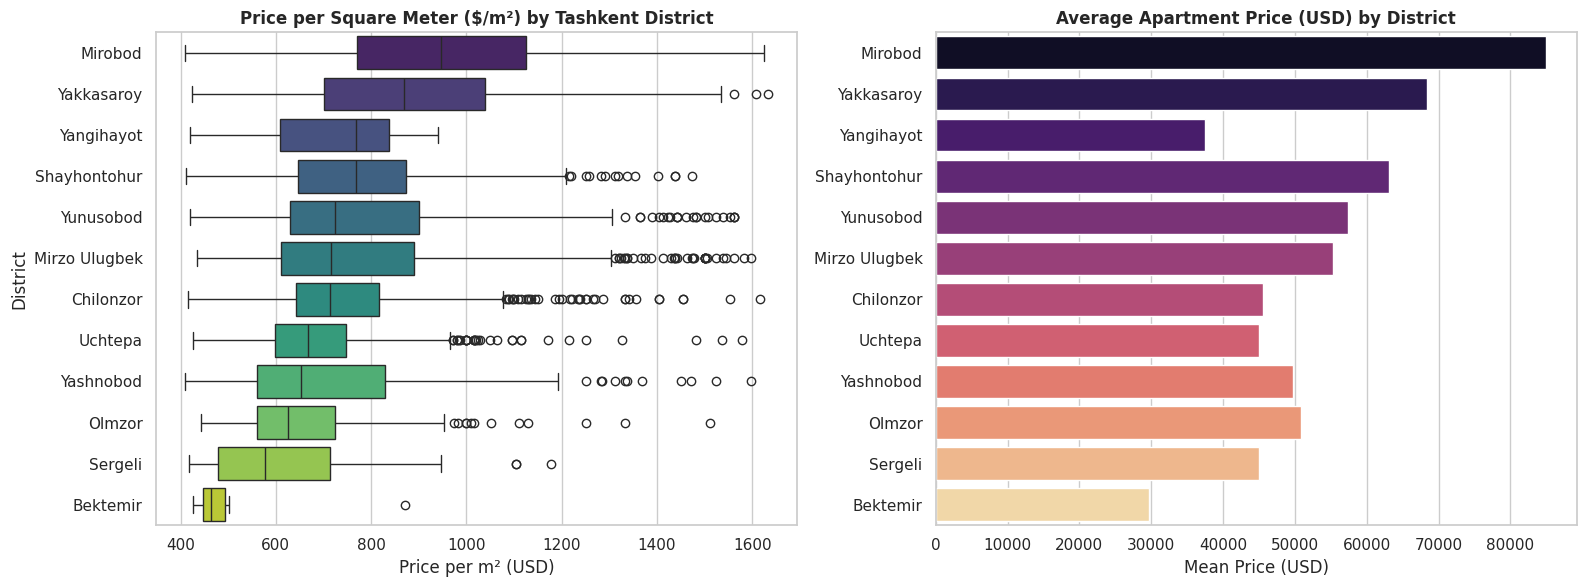

,Listings,Mean_Price,Median_Price,Mean_Price_Sqm
district,,,,
Mirobod,647,"85,016.50","76,000.00",956.73
Yakkasaroy,529,"68,346.93","55,000.00",891.64
Yangihayot,12,"37,416.67","38,500.00",737.38
Shayhontohur,325,"63,143.50","56,000.00",790.03
Yunusobod,779,"57,445.20","50,000.00",785.20
Mirzo Ulugbek,1136,"55,329.00","46,000.00",775.52
Chilonzor,1459,"45,506.46","39,500.00",737.99
Uchtepa,788,"44,947.07","42,000.00",686.15
Yashnobod,393,"49,793.12","42,000.00",713.19


In [7]:
# Visualizing district-level pricing and market share
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Order districts by median price per sqm
district_order = df_clean.groupby('district')['price_per_sqm'].median().sort_values(ascending=False).index

sns.boxplot(data=df_clean, y='district', x='price_per_sqm', order=district_order, palette='viridis', ax=axes[0])
axes[0].set_title('Price per Square Meter ($/m²) by Tashkent District', fontweight='bold')
axes[0].set_xlabel('Price per m² (USD)')
axes[0].set_ylabel('District')

district_summary = df_clean.groupby('district').agg(
    Listings=('price', 'count'),
    Mean_Price=('price', 'mean'),
    Median_Price=('price', 'median'),
    Mean_Price_Sqm=('price_per_sqm', 'mean')
).loc[district_order]

sns.barplot(x=district_summary['Mean_Price'], y=district_summary.index, palette='magma', ax=axes[1])
axes[1].set_title('Average Apartment Price (USD) by District', fontweight='bold')
axes[1].set_xlabel('Mean Price (USD)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

display(district_summary)

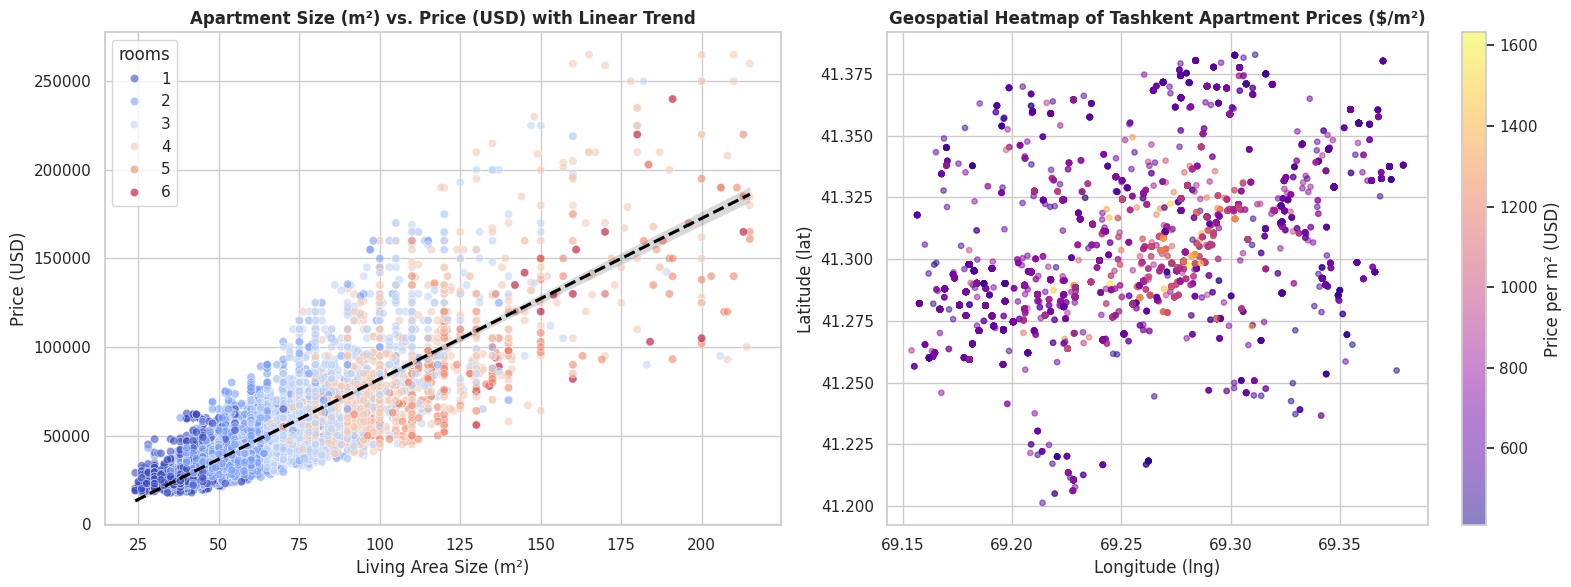

In [8]:
# Analyzing size vs price relationship and spatial distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot of Size vs Price colored by Rooms
sns.scatterplot(
    data=df_clean,
    x='size',
    y='price',
    hue='rooms',
    palette='coolwarm',
    alpha=0.6,
    ax=axes[0]
)
sns.regplot(data=df_clean, x='size', y='price', scatter=False, ax=axes[0], color='black', line_kws={'linestyle':'--'})
axes[0].set_title('Apartment Size (m²) vs. Price (USD) with Linear Trend', fontweight='bold')
axes[0].set_xlabel('Living Area Size (m²)')
axes[0].set_ylabel('Price (USD)')

# Geospatial Plot of Tashkent Listings colored by Price per m²
geo_filter = df_clean[
    (df_clean['lat'].between(41.20, 41.39)) &
    (df_clean['lng'].between(69.15, 69.38))
]
sc = axes[1].scatter(
    geo_filter['lng'],
    geo_filter['lat'],
    c=geo_filter['price_per_sqm'],
    cmap='plasma',
    alpha=0.5,
    s=15
)
plt.colorbar(sc, ax=axes[1], label='Price per m² (USD)')
axes[1].set_title('Geospatial Heatmap of Tashkent Apartment Prices ($/m²)', fontweight='bold')
axes[1].set_xlabel('Longitude (lng)')
axes[1].set_ylabel('Latitude (lat)')

plt.tight_layout()
plt.show()

## 5. Feature Engineering for Multiple Linear Regression
To maximize the predictive power of our **Multiple Linear Regression** model without leaking the target variable (`price`), we engineer meaningful domain features from the existing columns:

- `dist_from_center_km`: Haversine distance (in km) from Tashkent's central landmark (Amir Temur Square: `lat=41.3111, lng=69.2797`). Central apartments command a steep premium!
- `relative_floor`: Ratio of `level / max_levels` (captures where the unit sits vertically in the building).
- `is_top_floor`: Binary indicator (`1` if `level == max_levels`, else `0`). Top floors in older buildings often sell at a slight discount.
- `is_first_floor`: Binary indicator (`1` if `level == 1`, else `0`).
- `sqm_per_room`: Average room spaciousness (`size / rooms`).
- **One-Hot Encoding (`pd.get_dummies`)**: Convert categorical `district` into binary indicator variables (`drop_first=True` to avoid the Dummy Variable Trap / perfect multicollinearity).

> ⚠️ **Important Note on Data Leakage:** We drop `address` (too granular/text) and `price_per_sqm` (since `price_per_sqm` uses `price` in its formula, including it as an input feature would cause target leakage).

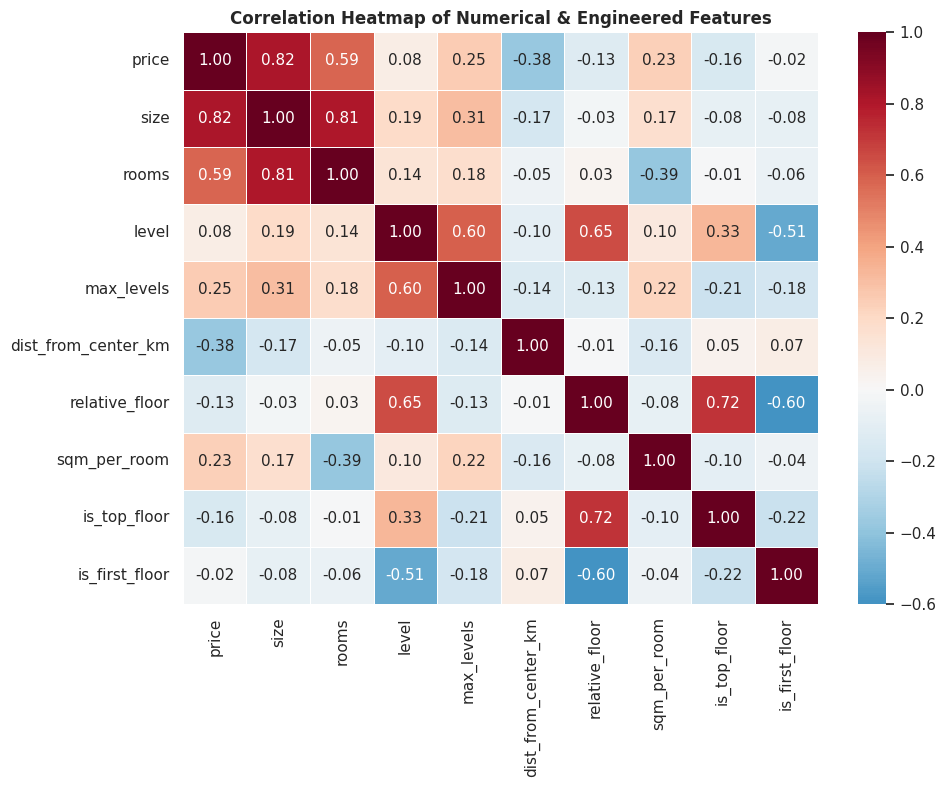

In [9]:
# Engineering spatial and structural real estate features
def haversine_distance(lat1, lon1, lat2=41.3111, lon2=69.2797):
    """Calculate distance (in km) from each apartment to Amir Temur Square (Tashkent Center)."""
    R = 6371.0  # Earth radius in kilometers
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2.0)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2.0)**2
    return 2 * R * np.arcsin(np.sqrt(a))

df_fe = df_clean.copy()

# Engineer domain features
df_fe['dist_from_center_km'] = haversine_distance(df_fe['lat'], df_fe['lng'])
df_fe['relative_floor'] = df_fe['level'] / df_fe['max_levels']
df_fe['is_top_floor'] = (df_fe['level'] == df_fe['max_levels']).astype(int)
df_fe['is_first_floor'] = (df_fe['level'] == 1).astype(int)

# Correlation matrix of numerical features with Price
num_cols = ['price', 'size', 'rooms', 'level', 'max_levels', 'dist_from_center_km', 'relative_floor', 'sqm_per_room', 'is_top_floor', 'is_first_floor']
plt.figure(figsize=(10, 8))
sns.heatmap(df_fe[num_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, linewidths=0.5)
plt.title('Correlation Heatmap of Numerical & Engineered Features', fontweight='bold')
plt.tight_layout()
plt.show()

In [10]:
# One-hot encoding districts and exporting clean dataset
model_cols = [
    'price', 'size', 'rooms', 'level', 'max_levels',
    'lat', 'lng', 'dist_from_center_km', 'relative_floor',
    'sqm_per_room', 'is_top_floor', 'is_first_floor', 'district'
]

df_model = pd.get_dummies(df_fe[model_cols], columns=['district'], drop_first=True, dtype=int)

# Save both human-readable cleaned data and MLR-ready encoded data
df_clean.to_csv('uybor_cleaned_eda.csv', index=False)
df_model.to_csv('uybor_mlr_ready.csv', index=False)

print(f'✅ Saved clean EDA dataset: uybor_cleaned_eda.csv ({df_clean.shape})')
print(f'✅ Saved MLR-ready encoded dataset: uybor_mlr_ready.csv ({df_model.shape})')
display(df_model.head())

✅ Saved clean EDA dataset: uybor_cleaned_eda.csv ((6449, 11))
✅ Saved MLR-ready encoded dataset: uybor_mlr_ready.csv ((6449, 23))


,price,size,rooms,level,max_levels,lat,lng,dist_from_center_km,relative_floor,sqm_per_room,is_top_floor,is_first_floor,district_Chilonzor,district_Mirobod,district_Mirzo Ulugbek,district_Olmzor,district_Sergeli,district_Shayhontohur,district_Uchtepa,district_Yakkasaroy,district_Yangihayot,district_Yashnobod,district_Yunusobod
0,52000,57.00,3,4,4,41.37,69.28,6.71,1.00,19.00,1,0,0,0,0,0,0,0,0,0,0,0,1
1,56000,52.00,2,4,5,41.29,69.26,2.71,0.80,26.00,0,0,0,0,0,0,0,0,0,1,0,0,0
2,37000,42.00,2,4,4,41.28,69.22,5.77,1.00,21.00,1,0,1,0,0,0,0,0,0,0,0,0,0
3,49500,65.00,3,1,4,41.29,69.20,7.30,0.25,21.67,0,1,1,0,0,0,0,0,0,0,0,0,0
4,55000,70.00,3,3,5,41.30,69.21,5.88,0.60,23.33,0,0,1,0,0,0,0,0,0,0,0,0,0


## 6. Multiple Linear Regression (MLR) Modeling & Evaluation
Now that our dataset is clean and encoded, we train and evaluate our **Multiple Linear Regression** model:
$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_k x_k$$

We split the data into **80% Training** and **20% Testing** sets, and evaluate using:
- $R^2$ **(Coefficient of Determination):** Proportion of variance in apartment prices explained by the model.
- **MAE (Mean Absolute Error):** Average absolute dollar difference between predicted and actual price.
- **RMSE (Root Mean Squared Error):** Penalizes larger prediction errors.
- **5-Fold Cross-Validation:** Confirms the model generalizes reliably across unseen folds.

In [11]:
# Training Multiple Linear Regression and evaluating metrics
X = df_model.drop(columns=['price'])
y = df_model['price']

# 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Fit Standard Unscaled Multiple Linear Regression (for direct dollar interpretation)
mlr_model = LinearRegression()
mlr_model.fit(X_train, y_train)

# Predictions
y_train_pred = mlr_model.predict(X_train)
y_test_pred = mlr_model.predict(X_test)

# Metrics Calculation
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
cv_scores = cross_val_score(mlr_model, X, y, cv=5, scoring='r2')

print('=========================================================')
print('   MULTIPLE LINEAR REGRESSION PERFORMANCE SUMMARY')
print('=========================================================')
print(f'Training R² Score          : {train_r2:.4f} ({train_r2*100:.2f}%)')
print(f'Testing R² Score           : {test_r2:.4f} ({test_r2*100:.2f}%)')
print(f'5-Fold Cross-Validated R²  : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')
print(f'Mean Absolute Error (MAE)  : ${test_mae:,.2f}')
print(f'Root Mean Sq. Error (RMSE) : ${test_rmse:,.2f}')
print('=========================================================')

   MULTIPLE LINEAR REGRESSION PERFORMANCE SUMMARY
Training R² Score          : 0.7578 (75.78%)
Testing R² Score           : 0.7705 (77.05%)
5-Fold Cross-Validated R²  : 0.7559 ± 0.0073
Mean Absolute Error (MAE)  : $10,432.52
Root Mean Sq. Error (RMSE) : $15,400.16


Model Intercept (Base Value): $5,153,092.14



,Feature,Coefficient ($ Impact per Unit)
12,district_Mirobod,"20,719.98"
13,district_Mirzo Ulugbek,"17,926.12"
18,district_Yakkasaroy,"17,376.03"
19,district_Yangihayot,"15,913.32"
21,district_Yunusobod,"14,795.95"
20,district_Yashnobod,"11,284.91"
11,district_Chilonzor,"11,059.91"
16,district_Shayhontohur,"9,659.69"
15,district_Sergeli,"9,241.51"
17,district_Uchtepa,"9,204.46"


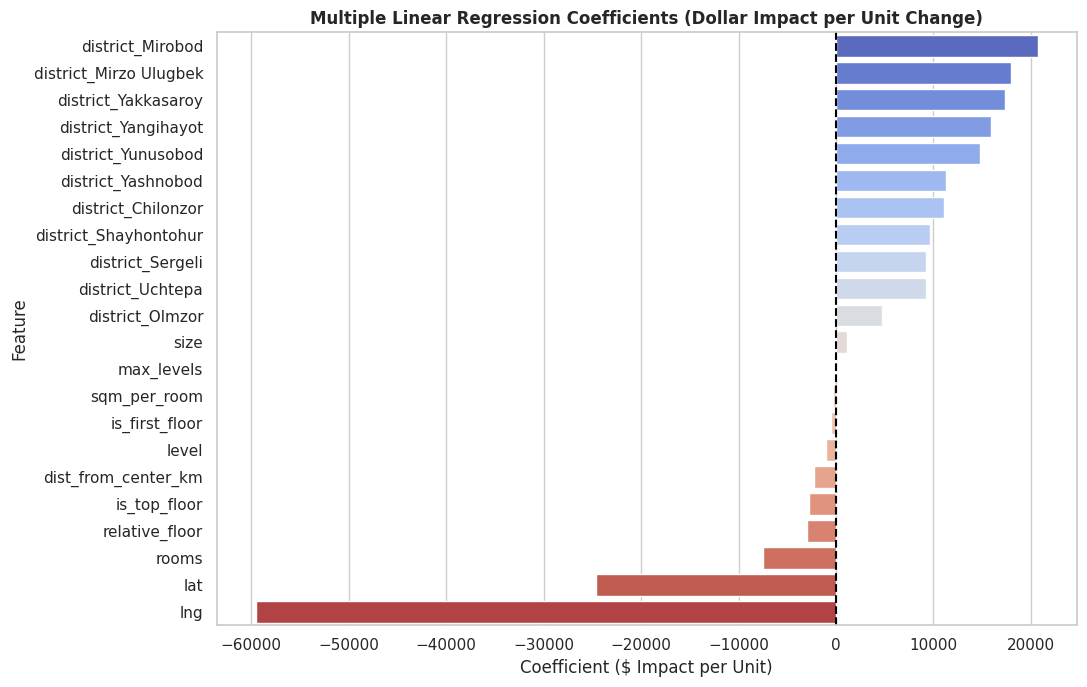

In [12]:
# Extracting and plotting regression feature coefficients
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient ($ Impact per Unit)': mlr_model.coef_
}).sort_values(by='Coefficient ($ Impact per Unit)', ascending=False)

print(f'Model Intercept (Base Value): ${mlr_model.intercept_:,.2f}\n')
display(coef_df)

plt.figure(figsize=(11, 7))
sns.barplot(data=coef_df, x='Coefficient ($ Impact per Unit)', y='Feature', palette='coolwarm')
plt.axvline(0, color='black', linestyle='--')
plt.title('Multiple Linear Regression Coefficients (Dollar Impact per Unit Change)', fontweight='bold')
plt.tight_layout()
plt.show()

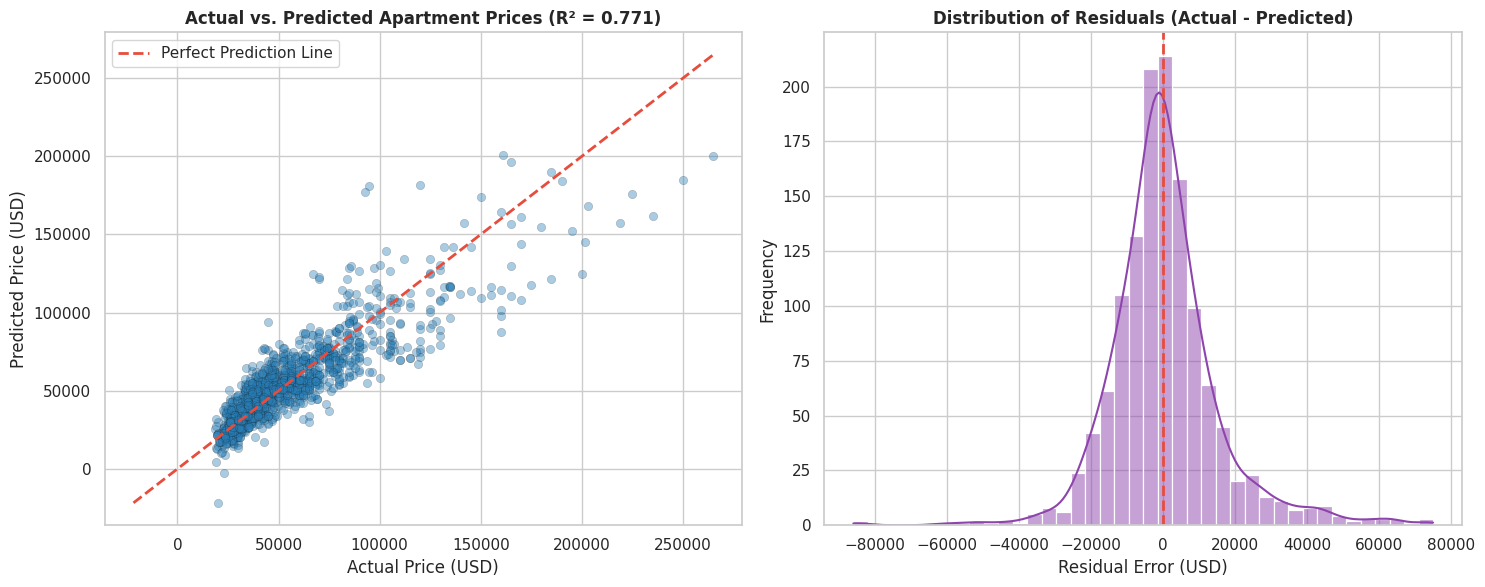

In [13]:
# Visualizing actual vs predicted prices and residual diagnostics
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Actual vs Predicted Scatter Plot
axes[0].scatter(y_test, y_test_pred, alpha=0.4, color='#2980b9', edgecolors='k', linewidth=0.3)
min_val, max_val = min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], color='#e74c3c', lw=2, linestyle='--', label='Perfect Prediction Line')
axes[0].set_title(f'Actual vs. Predicted Apartment Prices (R² = {test_r2:.3f})', fontweight='bold')
axes[0].set_xlabel('Actual Price (USD)')
axes[0].set_ylabel('Predicted Price (USD)')
axes[0].legend()

# 2. Residual Distribution (Checking Normality of Errors)
sns.histplot(residuals, bins=40, kde=True, ax=axes[1], color='#8e44ad')
axes[1].axvline(0, color='#e74c3c', linestyle='--', lw=2)
axes[1].set_title('Distribution of Residuals (Actual - Predicted)', fontweight='bold')
axes[1].set_xlabel('Residual Error (USD)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

## 7. Interactive Apartment Price Predictor
Run this cell to predict the fair market price of any apartment in Tashkent using the trained Multiple Linear Regression model.

In [14]:
# Building custom apartment price prediction helper
def predict_tashkent_apartment(size, rooms, level, max_levels, district, lat=41.3111, lng=69.2797):
    """Predicts the fair market value of a Tashkent apartment using our trained MLR model."""
    input_data = pd.DataFrame(0, index=[0], columns=X.columns)

    # Populate numerical & engineered features
    input_data['size'] = size
    input_data['rooms'] = rooms
    input_data['level'] = level
    input_data['max_levels'] = max_levels
    input_data['lat'] = lat
    input_data['lng'] = lng
    input_data['dist_from_center_km'] = haversine_distance(lat, lng)
    input_data['relative_floor'] = level / max_levels
    input_data['sqm_per_room'] = size / rooms
    input_data['is_top_floor'] = int(level == max_levels)
    input_data['is_first_floor'] = int(level == 1)

    # Set one-hot encoded district column if present
    dist_col = f'district_{district}'
    if dist_col in input_data.columns:
        input_data[dist_col] = 1

    predicted_price = mlr_model.predict(input_data)[0]
    print(f'🏠 Apartment Spec : {rooms}-room, {size} m², Floor {level}/{max_levels} in {district}')
    print(f'💰 Predicted Fair Market Price: ${predicted_price:,.2f} USD (${predicted_price/size:,.0f}/m²)\n')
    return predicted_price

# Example Predictions across different Tashkent districts
predict_tashkent_apartment(size=75, rooms=3, level=4, max_levels=9, district='Mirzo Ulugbek', lat=41.328, lng=69.332)
predict_tashkent_apartment(size=65, rooms=2, level=3, max_levels=5, district='Yakkasaroy', lat=41.288, lng=69.255)
predict_tashkent_apartment(size=55, rooms=2, level=2, max_levels=4, district='Chilonzor', lat=41.278, lng=69.202)

🏠 Apartment Spec : 3-room, 75 m², Floor 4/9 in Mirzo Ulugbek
💰 Predicted Fair Market Price: $60,251.07 USD ($803/m²)

🏠 Apartment Spec : 2-room, 65 m², Floor 3/5 in Yakkasaroy
💰 Predicted Fair Market Price: $63,905.79 USD ($983/m²)

🏠 Apartment Spec : 2-room, 55 m², Floor 2/4 in Chilonzor
💰 Predicted Fair Market Price: $43,529.02 USD ($791/m²)



np.float64(43529.01753285155)